В этом ноутбуке вы познакомитесь с такими генеративными моделями, как генеративные состязательные сети (GAN). Каждая модель имеет свои сильные и слабые стороны, например, GAN генерирует качественные изображения, но имеет проблемы с разнообразием. Этот эффект называется коллапсированием мод (mode collapse). На практике важно понимать причины возникновения коллапсирования мод и как с этим бороться.


Статьи и блог-посты о GAN:

- [Generative Adversarial Networks](https://arxiv.org/abs/1406.2661)

- [How to Train GAN](https://github.com/soumith/ganhacks)

- [Towards Principled Methods for Training Generative Adversarial Networks](https://arxiv.org/abs/1701.04862)

- [Wasserstein GAN](https://arxiv.org/abs/1701.07875)

- [From GAN to WGAN](https://lilianweng.github.io/posts/2017-08-20-gan/)

- [Improved Training of Wasserstein GANs](https://arxiv.org/abs/1704.00028)

- [WGAN-GP](https://arxiv.org/pdf/1704.00028.pdf)

- [f-GAN: Training Generative Neural Samplers using Variational Divergence Minimization](https://arxiv.org/abs/1606.00709)

- [Greedification Operators for Policy Optimization: Investigating Forward and Reverse KL Divergences](https://jmlr.org/papers/volume23/21-054/21-054.pdf)

- [Разные реализации](https://github.com/eriklindernoren/PyTorch-GAN/tree/master)

- [DCGAN](https://arxiv.org/pdf/1511.06434.pdf)


Ноутбук во многом опирается на [этот конспект](https://github.com/mmp-practicum-team/mmp_dl_spring_2025/blob/main/Seminars/22-gan-practice/gan-practice.ipynb).

[По ссылке](https://wandb.ai/nakhodnov17/mmp_practicum_spring_2024%7CSeminar%2011%7CWGAN-GP/runs/o7qnv1aq?nw=nwusernakhodnov17) можно посмотреть логи `wandb` для всех экспериментов.

<font color='OrangeRed'>**Важно:**</font> желательно использовать GPU, в ином случае модель будет учиться долго.

---

Для начала нам необходимо загрузить библиотеки. Также, мы установим режим вывода графиков в векторные форматы.

In [37]:
!pip install ml_collections -q

In [38]:
import os
import time
import random

import wandb
from tqdm.notebook import tqdm

import numpy as np
import matplotlib_inline
import matplotlib.pyplot as plt
from ml_collections import ConfigDict
from scipy.stats import norm

import torch
from torch.utils.data import TensorDataset, DataLoader
from torchvision.datasets import MNIST

from torchvision.utils import make_grid
import torchvision.transforms as transforms

%matplotlib inline
matplotlib_inline.backend_inline.set_matplotlib_formats('pdf', 'svg')

Обучение генеративных моделей, особенно GAN, крайне стохастическое, поэтому мы особенно внимательно будем следить за воспроизводимостью.

In [39]:
def set_global_seed(seed: int) -> None:
    """
    Set global seed for reproducibility.
    """

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    random.seed(seed)
    np.random.seed(seed)

set_global_seed(42)

## 1. Дивергенция

<font color='DarkOrange'>**Вопрос (?)**</font> Как можно оценить близость двух вероятностных распределений? Какие способы вы знаете?

Далее будем использовать стандартные обозначения:

\begin{align}
 &\pi(x) \text{ — распределение данных,}\\
 &p(x \mid \mu, \sigma) \text{ — распределение, в котором мы обучаем параметры $\mu$, $\sigma$}.
\end{align}

В нашем примере $p(x \mid \mu, \sigma)$ — генеративная модель.

При оптимизации дивергенции Кульбака-Лейблера наблюдаются эффекты **mean-seeking**, **mode-seeking**, которые возникают при оптимизации **forward** и **reverse** дивергенции соответсвенно. Напоминим, что:


\begin{align}
 &\textbf{Forward — } \text{KL}(\pi(x) \| p(x \mid \mu, \sigma)), \\
 &\textbf{Backward — } \text{KL}(p(x \mid \mu, \sigma) \| \pi(x)).
\end{align}

Наша первая цель - воспроизвести эти эффекты на практике. Для этого мы постраемся смоделировать смесь распределения с помощью унимодального распределения, то есть наша генеративная модель будет менее выразительна, чем распределение данных. На практике такое происходит часто, например, распределение изображений достаточно сложное для моделирования нейронной сетью размером менее чем миллиард параметров. Для реализации смеси распределений и других вероятностных объектов, будем использовать модуль `torch.distributions`.

В `torch.distributions` реализованы все стандартные распределения, подсчет KL-дивергенции, сэмплирование случайных величин `.sample()` и дифференцируемое по параметрам сэмплирование случайных величин `.rsample()` (не для всех распределений это возможно). Много чего реализовано в очень удобном формате, например, смеси распределений и вычисления скор-функции.

Подробнее можно почитать [в документации](https://pytorch.org/docs/stable/distributions.html).

Чтобы задать нормальное распределение, нам достаточно воспользоваться классом `torch.distributions.Normal`.

In [40]:
single_gaussian = torch.distributions.Normal(
    loc=torch.tensor(0.),
    scale=torch.tensor(1.)
)

Зададим распределение данных, которое будем моделировать смесью нормальных распределений.

\begin{align}
&\pi(x) = 0.8 p_1(x) + 0.2 p_2(x)\\
&p_1(x) = \mathcal{N}(x \mid -2, \frac{1}{4})\\
&p_2(x) = \mathcal{N}(x \mid 2, \frac{1}{4})\\
\end{align}

In [41]:
mixture_gaussian = torch.distributions.MixtureSameFamily(
    mixture_distribution=torch.distributions.Categorical(probs=torch.tensor([0.8, 0.2])),
    component_distribution=torch.distributions.Normal(
        loc=torch.tensor([-2., 2.]),
        scale=torch.tensor([0.5, 0.5])
    )
)

In [42]:
@torch.no_grad()
def plot_distributions(X, real_log_prob, model_log_prob=None, title=None, ax=None):
    res1 = real_log_prob(X).exp()
    if model_log_prob is not None:
        res2 = model_log_prob(X).exp()

    if ax is None:
        (fig, ax), show = plt.subplots(1, 1, figsize=(6, 4)), True
    else:
        show = False

    ax.plot(X.numpy(), res1.numpy(), color='b', linewidth=3, label=r'$\pi(\mathbf{x})$')
    ax.fill_between(X.numpy(), np.zeros_like(X.numpy()), res1.numpy(),  color='b', alpha=0.2)

    if model_log_prob is not None:
        ax.plot(X.numpy(), res2.numpy(), 'g', linewidth=3, label=r'$p(\mathbf{x} | \mu, \sigma)$')
        ax.fill_between(X.numpy(), np.zeros_like(X.numpy()), res2.numpy(),  color='g', alpha=0.2)

    if title is not None:
        ax.set_title(title)

    ax.legend()
    ax.grid(True)
    ax.set_xlabel('support')

    if show:
        fig.tight_layout()
        plt.show()

Визуализируем плотности вероятностей соотвествующих распределений.

In [43]:
X = torch.linspace(-6, 6, 500, dtype=torch.float32)

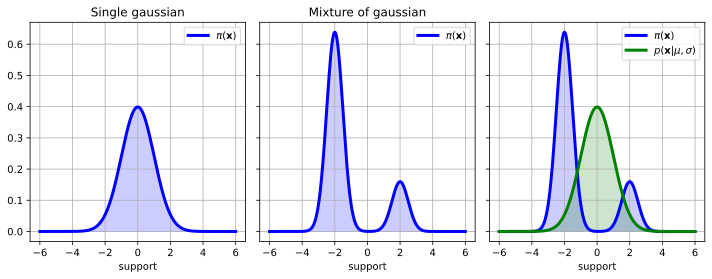

In [44]:
fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(10, 4))

plot_distributions(X, single_gaussian.log_prob, title='Single gaussian', ax=ax[0])
plot_distributions(X, mixture_gaussian.log_prob, title='Mixture of gaussian', ax=ax[1])
plot_distributions(X, mixture_gaussian.log_prob, single_gaussian.log_prob, ax=ax[2])

plt.tight_layout()

Мы рассмотрим **Forward** и **Reverse** KL-дивергенцию и дивергенцию Йенсена — Шеннона.

\begin{align}
&\text{KL}(\pi || p) = \int \pi(x) \log \frac{\pi(x)}{p(x)}dx, \\
&\text{KL}(p || \pi) = \int p(x) \log \frac{p(x)}{\pi(x)}dx, \\
&\text{JSD}(\pi || p) = \frac{1}{2} \Bigg[ \text{KL}\Big(\pi(x) || \frac{\pi(x) + p(x)}{2}\Big) + \text{KL}\Big(p(x) || \frac{\pi(x) + p(x)}{2}\Big) \Bigg].
\end{align}

Мы параметризуем распределение $p$ гауссианой и будем обучать ее параметры.

In [45]:
def KLD(X, log_prob1, log_prob2):
    dt = (X.max() - X.min()) / len(X)
    return (log_prob1(X).exp() * (log_prob1(X) - log_prob2(X))).sum() * dt

def JSD(X, log_prob1, log_prob2):
    def log_prob_mean(x):
        prob_mean = (log_prob1(x).exp() + log_prob2(x).exp()) / 2.0
        return prob_mean.log()

    return (KLD(X, log_prob1, log_prob_mean) + KLD(X, log_prob2, log_prob_mean)) / 2.0

In [46]:
def get_trainable_gaussian(mu=-1.0, sigma=0.5):
    mu = torch.tensor(mu, requires_grad=True, dtype=torch.double)
    sigma = torch.tensor(sigma, requires_grad=True, dtype=torch.double)

    single_gaussian = torch.distributions.Normal(mu, sigma)
    optimizer = torch.optim.SGD([mu, sigma], lr=0.03)

    return single_gaussian, optimizer

In [47]:
forward_KL_loss_fn = lambda X, real_log_prob, model_log_prob: KLD(X, real_log_prob, model_log_prob)
reverse_KL_loss_fn = lambda X, real_log_prob, model_log_prob: KLD(X, model_log_prob, real_log_prob)
JSD_loss_fn = lambda X, real_log_prob, model_log_prob: JSD(X, real_log_prob, model_log_prob)

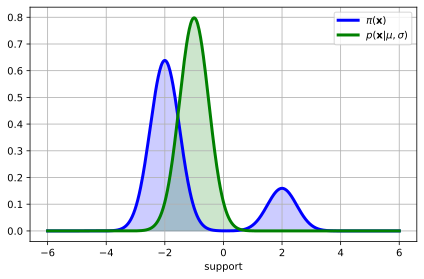

In [48]:
single_gaussian, _ = get_trainable_gaussian()

plot_distributions(X, mixture_gaussian.log_prob, single_gaussian.log_prob)

Для обучения напишем простой цикл обучения.

In [49]:
def solve_task(optimizer, loss_fn, real_log_prob, model_log_prob, epochs, verbose=True, freq=10):
    n_plots = (epochs // freq) * verbose + 2
    n_rows, n_cols = (n_plots - 1) // 3 + 1, 3
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2.5 * n_rows), sharex=True, sharey=True)
    axes = axes.reshape(-1)

    plot_distributions(X, real_log_prob, model_log_prob, title=f'Initialization', ax=axes[0])

    for epoch in range(epochs):
        optimizer.zero_grad()

        loss = loss_fn(X, real_log_prob, model_log_prob)
        loss.backward()
        optimizer.step()

        if verbose and epoch % freq == 0:
            plot_distributions(
                X, real_log_prob, model_log_prob,
                title=f'Step: {epoch}, loss: {loss:.2f}', ax=axes[epoch // 10 + 1]
            )

    plot_distributions(X, real_log_prob, model_log_prob, title=f'Final, loss: {loss:.2f}', ax=axes[-1])

    fig.tight_layout()
    plt.show()

Оптимизация forward дивергенции.

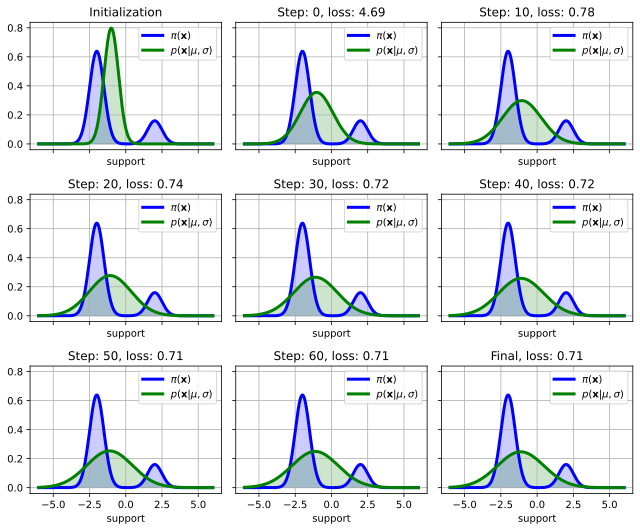

In [50]:
single_gaussian, optimizer = get_trainable_gaussian()

solve_task(optimizer, forward_KL_loss_fn, mixture_gaussian.log_prob, single_gaussian.log_prob, epochs=70)

Оптимизация reverse дивергенции.

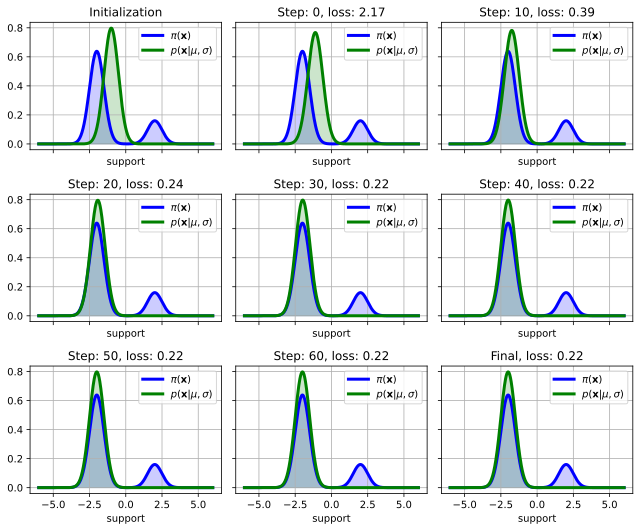

In [51]:
single_gaussian, optimizer = get_trainable_gaussian()

solve_task(optimizer, reverse_KL_loss_fn, mixture_gaussian.log_prob, single_gaussian.log_prob, epochs=70)

Исследуем, как ведет себя обучение в зависимости от разных иницилизаций. Наша цель - понять, как **mode-seeking** влияет на обучение.

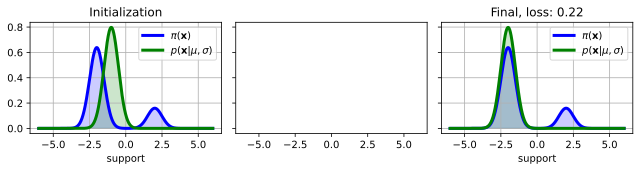

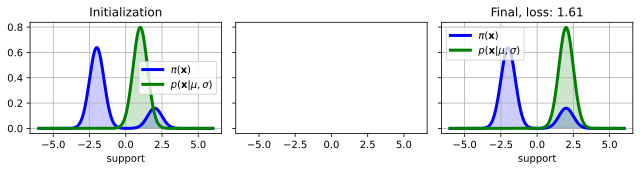

In [52]:
for mu in [-1.0, 1.0]:
    single_gaussian, optimizer = get_trainable_gaussian(mu=mu)
    solve_task(
        optimizer, reverse_KL_loss_fn, mixture_gaussian.log_prob, single_gaussian.log_prob,
        epochs=70, verbose=False
    )

<font color='DarkOrange'>**Вопрос (?)**</font> Как проявляется mode-seeking? Приведите пример из жизни, например, если модель обучилась на датасете собак разных пород.

Важно понять, переносятся ли эффект **mode-seeking** на дивергенцию Йенсена — Шеннона, так как именно её мы оптимизируем в классических `GAN` моделях.

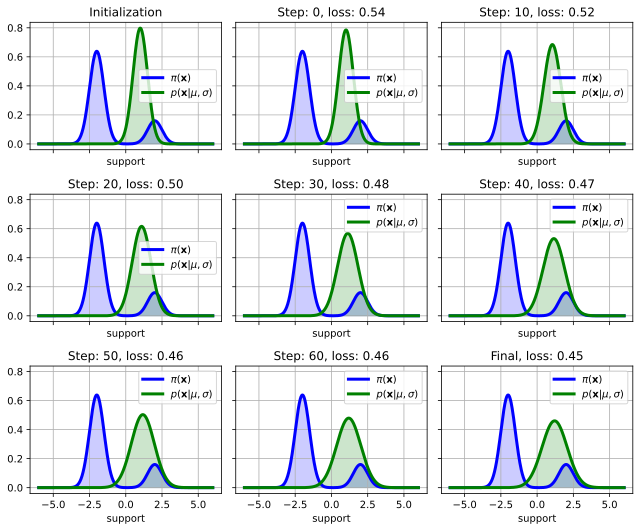

In [53]:
single_gaussian, optimizer = get_trainable_gaussian(mu=1.0)

solve_task(optimizer, JSD_loss_fn, mixture_gaussian.log_prob, single_gaussian.log_prob, epochs=70)

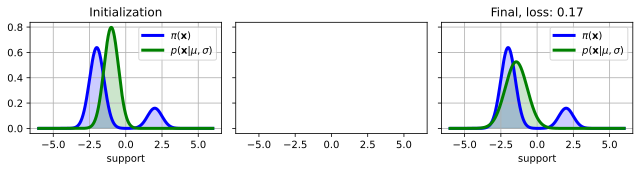

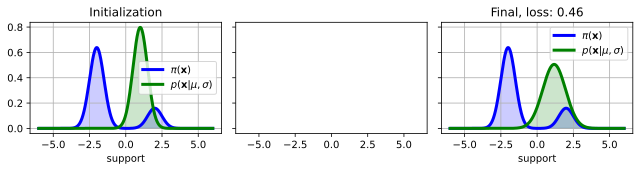

In [54]:
for mu in [-1.0, 1.0]:
    single_gaussian, optimizer = get_trainable_gaussian(mu=mu)
    solve_task(
        optimizer, JSD_loss_fn, mixture_gaussian.log_prob, single_gaussian.log_prob, epochs=50, verbose=False
    )

<font color='DarkOrange'>**Вопрос (?)**</font> Что мы ожидаем при обучении GAN на дивергенцию  Йенсена — Шеннона?

## 2. Обучение GAN на модельном примере

Посмотрим, как обучается `GAN` модели на модельном примере. Наша цель - рассмотреть, какие эффекты возникают при обучении: возникает ли колапсирование в моду (mode collapse), какие сэмплы получаются, как работает дискриминатор и как выглядит его предсказание.




<font color='DarkOrange'>**Вопрос (?)**</font>  Что должен выдавать идеальный дискриминатор, если генератор также обучен идеально?

In [55]:
def plot_gan_data(noise_fn, data_fn, data_pdf=None, samples=5000):
    noise = noise_fn(samples).numpy().flatten()
    target = data_fn(samples).numpy().flatten()

    fig, ax = plt.subplots(1, 1, figsize=(6, 4))

    ax.hist(noise, label='noise', alpha=0.5, density=True, color='b')
    ax.hist(target, label='target', alpha=0.5, density=True, color='g')
    if data_pdf is not None:
        x = np.linspace(-6, 6, 100)
        ax.plot(x, data_pdf(x), 'g', label='real distribution')

    ax.grid(True)
    ax.legend(loc='upper left')

    fig.tight_layout()
    plt.show()

def plot_gan_loss(loss_g, loss_d_real, loss_d_fake):
    fig, ax = plt.subplots(1, 2, figsize=(9, 3))

    ax[0].plot(loss_g)

    ax[1].plot(loss_d_real, label="real")
    ax[1].plot(loss_d_fake, label="fake")
    ax[1].plot(loss_d_real + loss_d_fake, label="all")

    ax[1].legend()

    ax[0].grid(True)
    ax[1].grid(True)

    ax[0].set_title("Generator loss")
    ax[1].set_title("Discriminator loss")

    fig.tight_layout()
    plt.show()

@torch.no_grad()
def visualize_GAN(gan, data_pdf=None, ax=None):
    size = 500
    x = np.linspace(-6, 6, 100)
    bins = np.linspace(-6, 6, 60)

    real_data = gan.data_fn(size)
    noise = gan.noise_fn(size)
    sampled_data = gan.generate_samples(noise)
    d_probs = gan.D(torch.from_numpy(x).float().unsqueeze(-1))

    if ax is None:
        (fig, ax), show = plt.subplots(1, 1, figsize=(6, 4)), True
    else:
        show = False

    ax.plot(x, d_probs.numpy(), 'b', label='D distribution')

    ax.hist(noise.numpy(), label='noise', alpha=0.5, density=True, color='b', bins=bins)
    ax.hist(real_data.numpy(), label='real data', alpha=0.5, density=True, color='g', bins=bins)
    ax.hist(sampled_data.numpy(), label='G samples', alpha=0.5, density=True, color='r', bins=bins)

    if data_pdf is not None:
        ax.plot(x, data_pdf(x), 'g', label='real distribution')

    ax.grid(True)
    ax.legend(loc='upper left')

    if show:
        fig.tight_layout()
        plt.show()

Напишем класс, который будет содержать в себе логику обучения GAN.

In [25]:
import torch

class VanillaGAN(torch.nn.Module):
    def __init__(
        self, G, D, noise_fn, data_fn, batch_size, lr_G=2e-4, lr_D=1e-3
    ):
        """Класс GAN для объединения и обучения Генератора и Дискриминатора.
        Args:
            G: нейросеть-Генератор
            D: нейросеть-Дискриминатор
            noise_fn: функция f(num: int) -> тензор PyTorch (латентные векторы шума)
            data_fn: функция f(num: int) -> тензор PyTorch (реальные батчи данных)
            batch_size: размер батча для обучения
            lr_G: скорость обучения (learning rate) для генератора
            lr_D: скорость обучения (learning rate) для дискриминатора
        """
        super().__init__()

        # Сохраняем архитектуры сетей
        self.G = G
        self.D = D

        # Сохраняем функции генерации шума и загрузки реальных данных
        self.noise_fn = noise_fn
        self.data_fn = data_fn

        self.batch_size = batch_size

        # Классическая функция потерь — бинарная кросс-энтропия (Binary Cross Entropy)
        self.criterion = torch.nn.BCELoss()

        # Инициализируем оптимизаторы Adam со специфичными для GAN значениями betas (0.5 для стабильности)
        self.optim_G = torch.optim.Adam(
            G.parameters(), lr=lr_G, betas=(0.5, 0.999)
        )
        self.optim_D = torch.optim.Adam(
            D.parameters(), lr=lr_D, betas=(0.5, 0.999)
        )

        # Регистрируем неизменяемые тензоры-метки (буферы), которые автоматически переносятся на GPU вместе с моделью.
        # target_zeros — метки «0» (фейк), target_ones — метки «1» (реальные данные).
        # persistent=False означает, что эти буферы не будут сохраняться в state_dict при сохранении весов модели.
        self.register_buffer(
            'target_zeros', torch.zeros((self.batch_size, 1), dtype=torch.float32), persistent=False
        )
        self.register_buffer(
            'target_ones', torch.ones((self.batch_size, 1), dtype=torch.float32), persistent=False
        )

    @torch.no_grad()
    def generate_samples(self, latents=None, n=None):
        """Генерация сэмплов из генератора без вычисления градиентов (для инференса/тестов).
        Args:
            latents: готовый тензор латентных векторов
            n: количество сэмплов для генерации
        """
        # Если латентные векторы не переданы, генерируем их с помощью noise_fn
        if latents is None:
            latents = self.noise_fn(self.batch_size if n is None else n)
        else:
            # Если латентный вектор передан, контролировать параметр `n` извне нельзя
            assert n is None

        # Пропускаем шум через Генератор и возвращаем фейковые данные
        return self.G(latents)

    def train_step_G(self):
        """Один шаг обучения генератора. Возвращает значение лосса."""
        # Сбрасываем градиенты оптимизатора генератора
        self.optim_G.zero_grad()

        # Сэмплируем новый батч случайного шума
        latents = self.noise_fn(self.batch_size)

        # Генерируем фейковые данные (градиенты здесь нужны, так как обучаем G)
        generated = self.G(latents)
        # Дискриминатор оценивает сгенерированные данные
        classifications = self.D(generated)

        # Считаем ошибку: генератор хочет, чтобы Дискриминатор поверил, что фейки — это «единицы» (реальные данные)
        loss = self.criterion(classifications, self.target_ones)

        # Обратный проход — считаем градиенты для Генератора
        loss.backward()

        # Обновляем веса Генератора
        self.optim_G.step()

        return loss.item()

    def train_step_D(self):
        """Один шаг обучения дискриминатора. Возвращает лоссы для реальных и фейковых данных."""
        # Сбрасываем градиенты оптимизатора дискриминатора
        self.optim_D.zero_grad()

        # --- 1. Обучение на реальных данных ---
        # Получаем батч настоящих данных
        real_samples = self.data_fn(self.batch_size)
        # Дискриминатор делает предсказание для реальных данных
        pred_real = self.D(real_samples)
        # Считаем ошибку: Дискриминатор должен классифицировать эти данные как «единицы»
        loss_real = self.criterion(pred_real, self.target_ones)

        # --- 2. Обучение на фейковых данных ---
        # Сэмплируем случайный шум
        latents = self.noise_fn(self.batch_size)
        # Генерируем фейки через метод generate_samples (Важно: там стоит @torch.no_grad(),
        # поэтому граф вычислений Генератора здесь отсекается, градиенты текут только через Дискриминатор)
        fake_samples = self.generate_samples(latents)
        # Дискриминатор делает предсказание для фейков
        pred_fake = self.D(fake_samples)
        # Считаем ошибку: Дискриминатор должен классифицировать фейки как «нули»
        loss_fake = self.criterion(pred_fake, self.target_zeros)

        # --- 3. Объединение лоссов и шаг оптимизации ---
        # Итоговый лосс — это среднее арифметическое лосса на реальных и лосса на фейковых данных
        loss = (loss_real + loss_fake) / 2
        # Обратный проход — считаем градиенты для Дискриминатора
        loss.backward()

        # Обновляем веса Дискриминатора
        self.optim_D.step()

        # Возвращаем значения ошибок для логирования
        return loss_real.item(), loss_fake.item()

Так как у нас модельный пример, то в качестве архитектур генеретора и дискриминатора мы будем рассматривать полносвязанные сети.

In [56]:
def get_simple_model(hidden_sizes):
    assert len(hidden_sizes) > 1

    network = torch.nn.Sequential()
    for in_features, out_features in zip(hidden_sizes[:-2], hidden_sizes[1:-1]):
        network.append(torch.nn.Linear(in_features, out_features))
        network.append(torch.nn.ReLU())

    network.append(torch.nn.Linear(hidden_sizes[-2], hidden_sizes[-1]))

    return network

Генератор принимает на вход случайные числа из диапозона $[-0.5, 0.5]$.

In [57]:
def noise_fn(x):
    return torch.rand((x, 1)) - 0.5

В качестве распределения данных мы будем также использовать смесь распределений. Кроме того, в этом примере мы будем считать правдоподобие сгенерированных данных, на практике в реальных задачах это почти всегда невозможно.

In [58]:
mixture_gaussian = torch.distributions.MixtureSameFamily(
    torch.distributions.Categorical(torch.tensor([0.7, 0.3])),
    torch.distributions.Normal(
        loc=torch.tensor([-3., 3.]),
        scale=torch.tensor([1., 1.])
    )
)

def data_fn(x):
    return mixture_gaussian.sample((x, 1))

def data_pdf(x):
    return mixture_gaussian.log_prob(torch.tensor(x)).exp().numpy()

Собирём всё вместе.

In [59]:
def get_GAN(G_hidden_sizes=(1, 64, 64, 64, 1), D_hidden_sizes=(1, 64, 64, 64, 1)):
    G = get_simple_model(G_hidden_sizes)
    D = get_simple_model(D_hidden_sizes).append(torch.nn.Sigmoid())

    gan = VanillaGAN(G, D, noise_fn, data_fn, batch_size=32)

    return gan

Мы будем визуализировать:

- Шум, который подали в генератор;
- Распределение данных;
- Датасет (сэмплы из расределения данных);
- Сэмплы, которые сгенерировал генератор;
- Выходы дискриминатора (распределение дискриминатора);

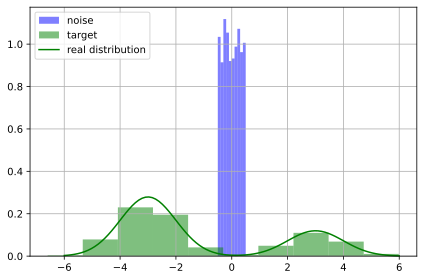

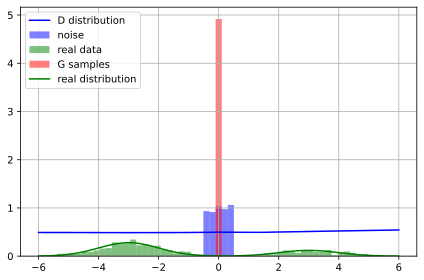

In [60]:
gan = get_GAN()

plot_gan_data(noise_fn, data_fn, data_pdf)
visualize_GAN(gan, data_pdf=data_pdf)

Напишем цикл обучения. Обратите внимание, что благодаря классу VanillaGAN цикл обучения выглядит очень похоже на цикл обучения обычного классификатора.

In [61]:
def train_1D_GAN(gan, n_batches=100, epochs=50, n_D_steps_per_G=1):
    # Внутренняя функция-помощник: определяет, нужно ли логировать/визуализировать текущую эпоху.
    # Рисуем графики каждую 10-ю эпоху, а также обязательно на самой последней эпохе.
    def is_logging_epoch(epoch):
        return (epoch % 10 == 0 or epoch == epochs - 1)

    # Фиксируем время старта для замера общей продолжительности обучения
    start_time = time.time()

    # Списки для сохранения средней ошибки генератора и дискриминатора по эпохам
    loss_g, loss_d_real, loss_d_fake = [], [], []

    # Главный цикл обучения по эпохам
    for epoch in range(epochs):
        # Переменные-аккумуляторы для суммирования лоссов внутри одной эпохи (для последующего усреднения)
        loss_g_running, loss_d_real_running, loss_d_fake_running = 0.0, 0.0, 0.0

        # Если текущая эпоха подлежит логированию, инициализируем сетку из 3 графиков (matplotlib)
        if is_logging_epoch(epoch):
            fig, axes = plt.subplots(1, 3, figsize=(10, 4), sharex=True, sharey=True)

        # Цикл итераций (батчей) внутри одной эпохи
        for idx in range(n_batches):

            # Визуализация СОСТОЯНИЯ №1: Самый первый батч эпохи, до каких-либо обновлений весов на этом шаге
            if idx == 0 and is_logging_epoch(epoch):
                axes[0].set_title('Train D for one batch: start')
                visualize_GAN(gan, data_pdf=data_pdf, ax=axes[0])

            # Обучаем Дискриминатор k раз (n_D_steps_per_G) на один шаг обучения Генератора.
            # Это классический прием для поддержания баланса сил, чтобы D не отставал от G.
            for _ in range(n_D_steps_per_G):
                # Делаем один шаг градиентного спуска для Дискриминатора
                loss_D_real_batch, loss_D_fake_batch = gan.train_step_D()
                # Аккумулируем ошибки
                loss_d_real_running += loss_D_real_batch
                loss_d_fake_running += loss_D_fake_batch

            # Визуализация СОСТОЯНИЯ №2: Тот же первый батч, но сразу ПОСЛЕ того, как обновился Дискриминатор,
            # но ДО того, как обновился Генератор. Позволяет увидеть локальный сдвиг разделяющей поверхности D.
            if idx == 0 and is_logging_epoch(epoch):
                axes[1].set_title('Train D for one batch: end')
                visualize_GAN(gan, data_pdf=data_pdf, ax=axes[1])

            # Делаем один шаг градиентного спуска для Генератора
            loss_G_batch = gan.train_step_G()
            # Аккумулируем ошибку генератора
            loss_g_running += loss_G_batch

        # По окончании эпохи считаем средний лосс для G (делим на общее число батчей)
        loss_g.append(loss_g_running / n_batches)
        # Считаем средний лосс для D (делим на общее число батчей, умноженное на количество шагов D на каждом батче)
        loss_d_real.append(loss_d_real_running / (n_batches * n_D_steps_per_G))
        loss_d_fake.append(loss_d_fake_running / (n_batches * n_D_steps_per_G))

        # Отрисовка результатов и вывод метрик, если эпоха логируемая
        if is_logging_epoch(epoch):
            # Формируем общий заголовок для всей фигуры с указанием эпохи, времени и последних средних лоссов
            fig.suptitle(
                "Epoch {0}/{1} ({2:.1f}s): G={3:.3f}, Dr={4:.3f}, Df={5:.3f}".format(
                    epoch + 1, epochs, time.time() - start_time,
                    loss_g[-1], loss_d_real[-1], loss_d_fake[-1]
                )
            )
            # Визуализация СОСТОЯНИЯ №3: Финальное распределение плотностей в самом конце эпохи
            axes[2].set_title('After epoch')
            visualize_GAN(gan, data_pdf=data_pdf, ax=axes[2])

            # Корректируем отступы между графиками и выводим фигуру на экран
            fig.tight_layout()
            plt.show()

    # Возвращаем историю лоссов в виде массивов NumPy для последующего построения общих графиков обучения
    return np.array(loss_g), np.array(loss_d_real), np.array(loss_d_fake)

Обучим модель и зафиксируем генераторы случайных чисел, так как нам важна воспроизводимость результатов. Будем обучать генератор каждую итерацию.



<font color='DarkOrange'>**Вопрос (?)**</font>  Почему обучать генератор каждую итерацию плохо?

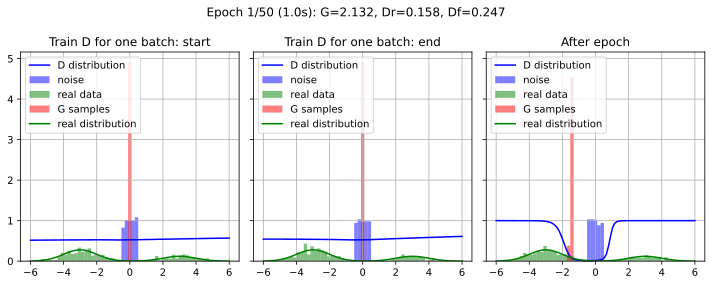

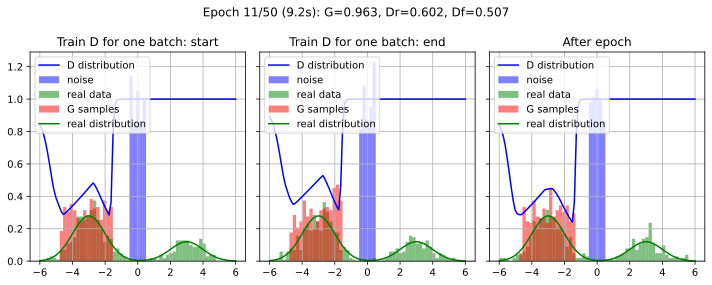

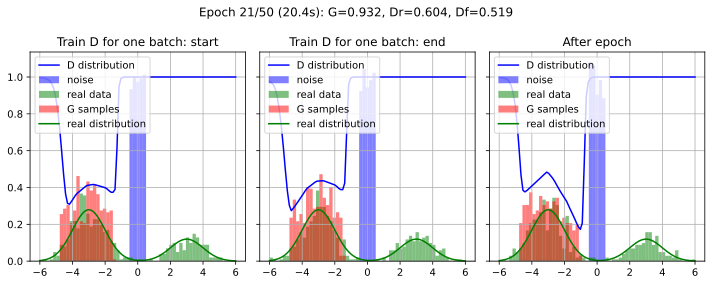

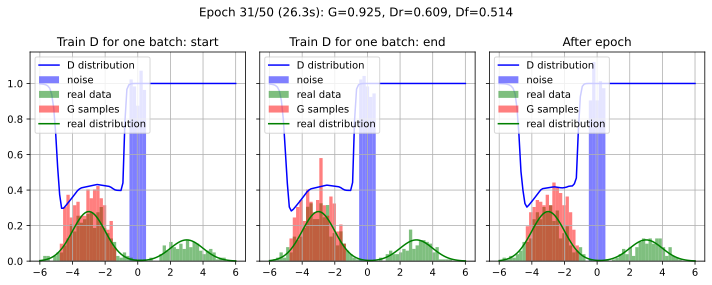

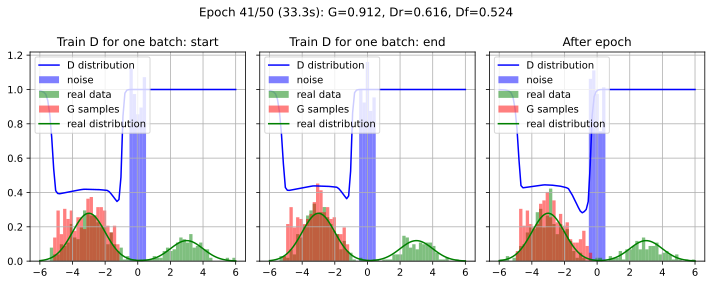

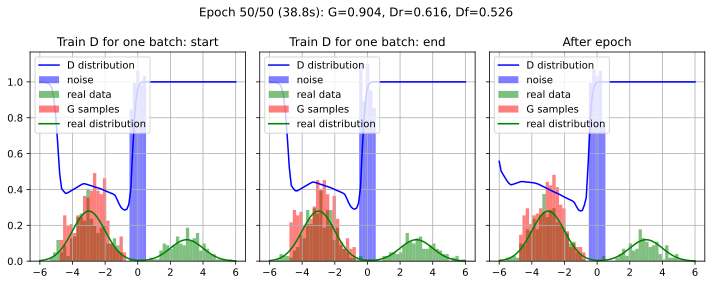

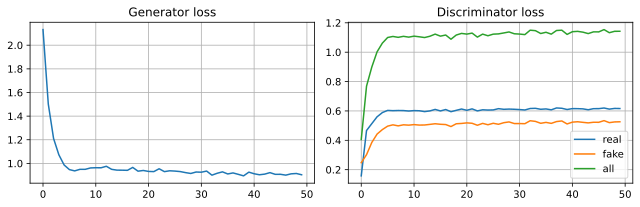

In [62]:
set_global_seed(0)

gan = get_GAN()
loss_g_1, loss_d_real_1, loss_d_fake_1 = train_1D_GAN(gan)
plot_gan_loss(loss_g_1, loss_d_real_1, loss_d_fake_1)

В итоге мы получили коллапсирование в левую моду. Обучим модель ещё раз при других инициализациях моделей.

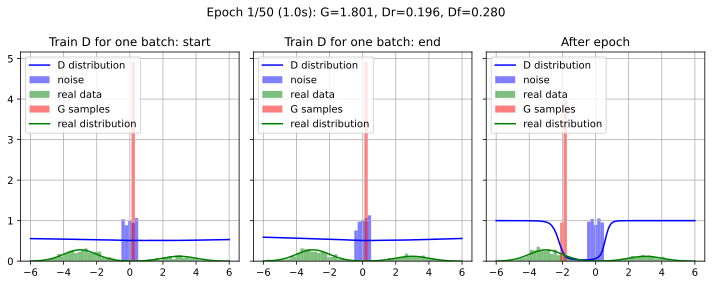

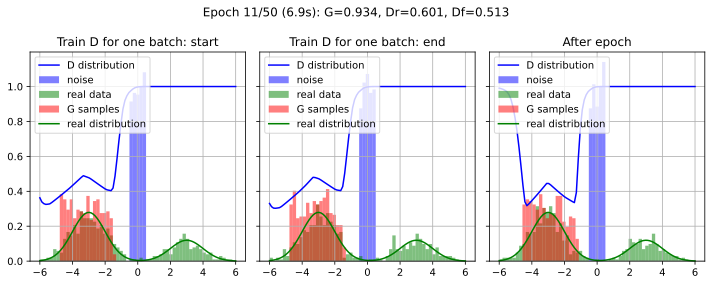

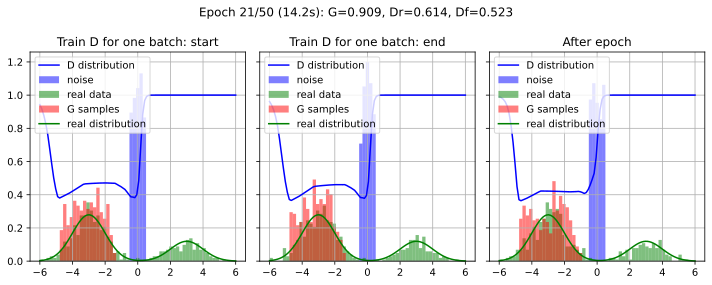

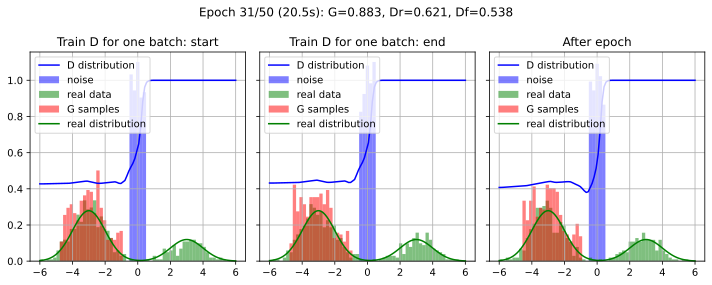

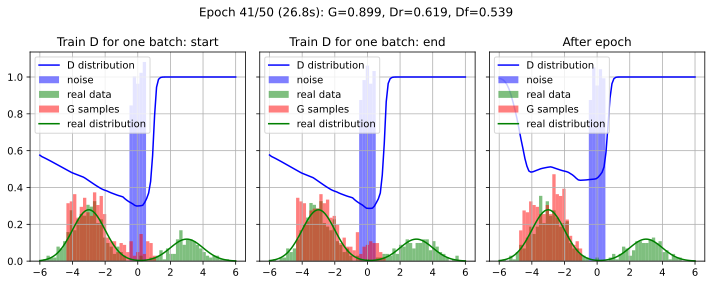

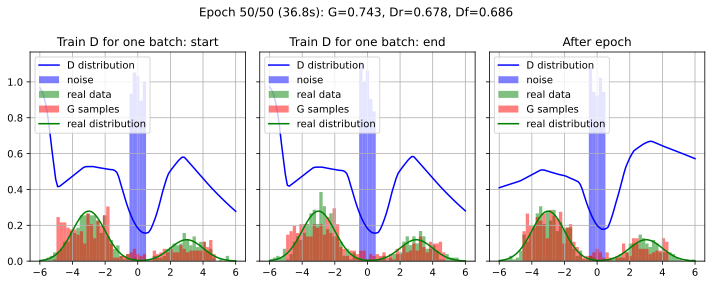

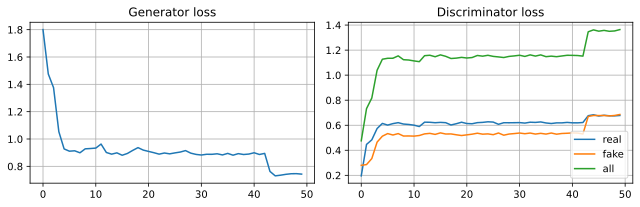

In [63]:
set_global_seed(3)

gan = get_GAN()
loss_g_1, loss_d_real_1, loss_d_fake_1 = train_1D_GAN(gan)
plot_gan_loss(loss_g_1, loss_d_real_1, loss_d_fake_1)

В конце у нас получилось засэмплировать из обеих мод, то есть модель обучилась хорошо. Попробуем теперь обучить модель, но обновлять генератор каждые 20 итераций обучений.

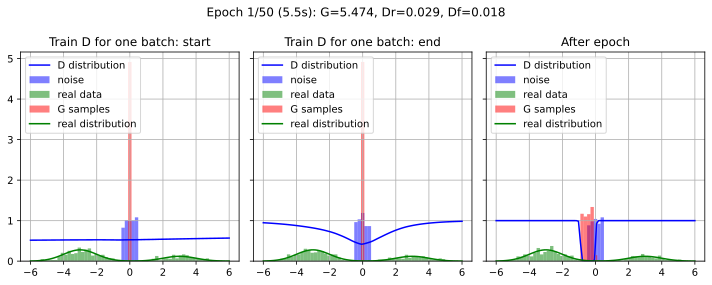

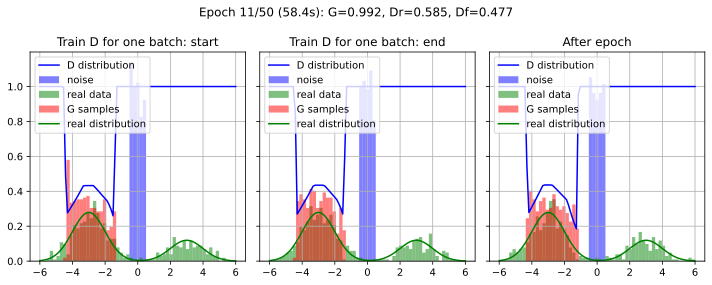

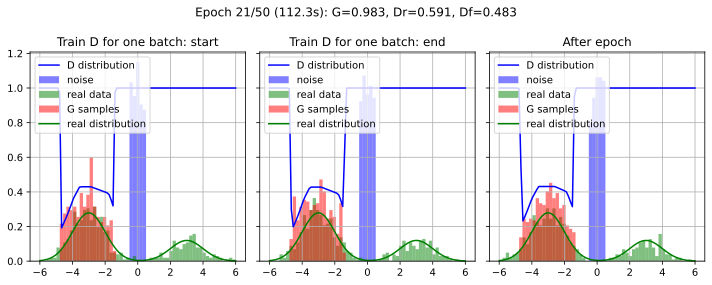

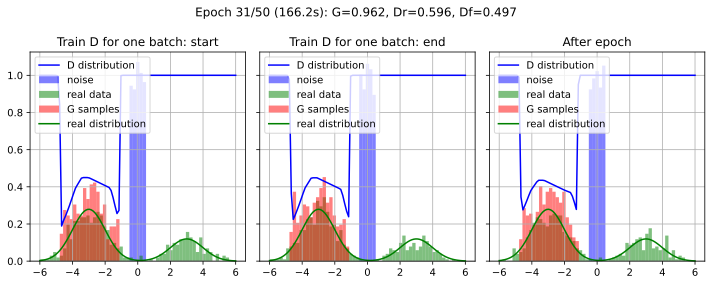

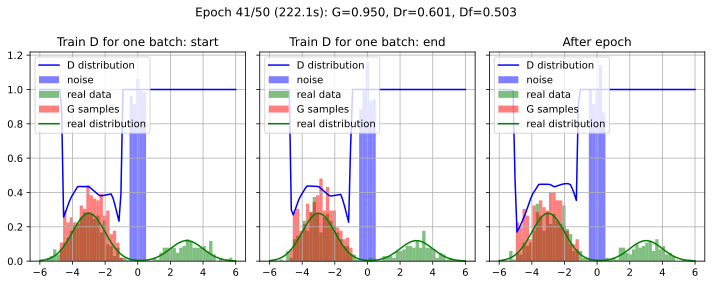

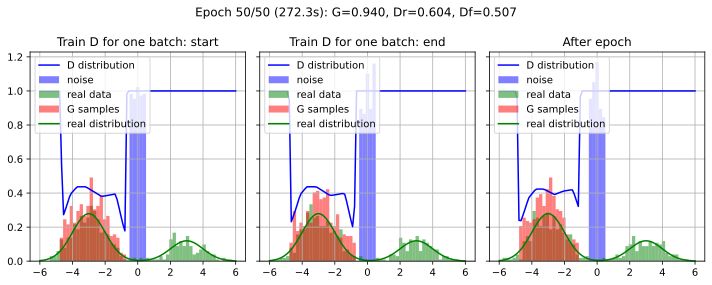

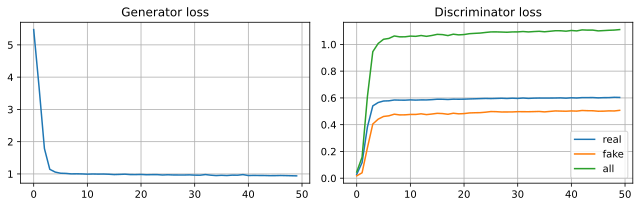

In [64]:
set_global_seed(0)

gan = get_GAN()
loss_g_20, loss_d_real_20, loss_d_fake_20 = train_1D_GAN(gan, n_D_steps_per_G=20)
plot_gan_loss(loss_g_20, loss_d_real_20, loss_d_fake_20)

Выше мы нашли инициализацию, при которой GAN обучается хорошо. Воспользуемся ей, для этого используем те же самые генераторы случайных чисел. Только теперь будем обучать генератор раз в 20 итераций.

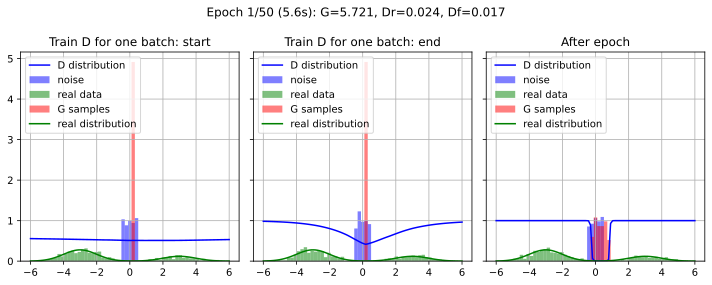

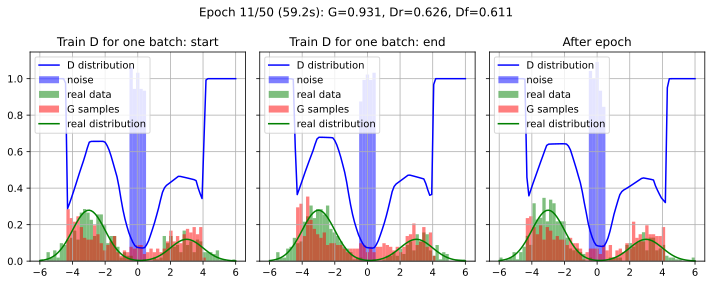

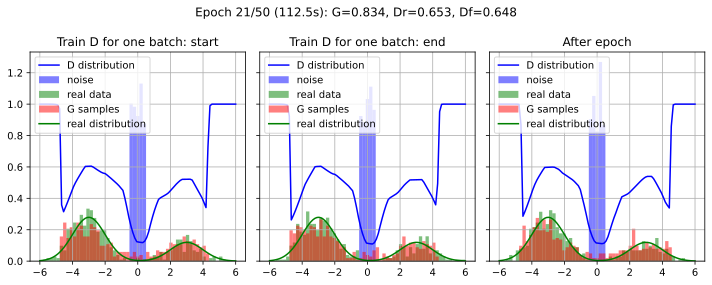

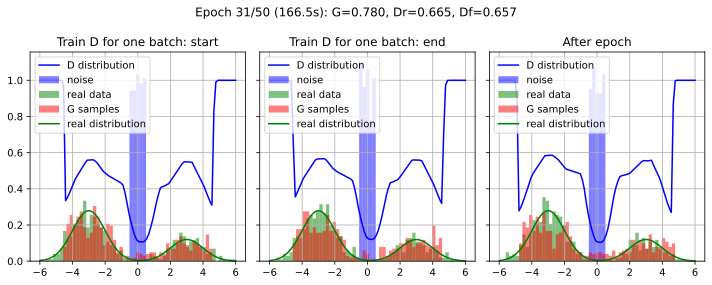

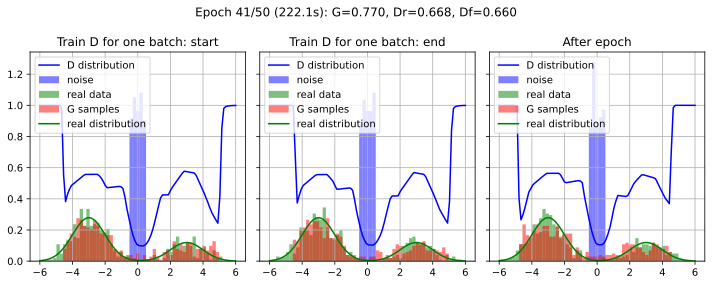

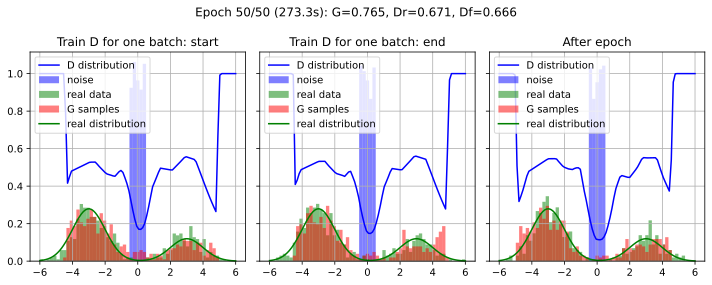

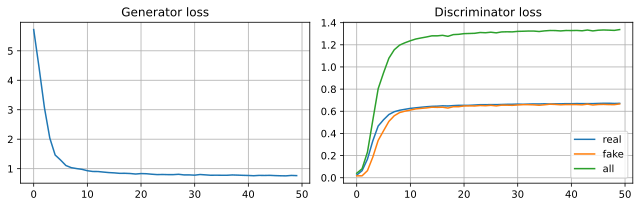

In [ ]:
set_global_seed(3)

gan = get_GAN()
loss_g_20, loss_d_real_20, loss_d_fake_20 = train_1D_GAN(gan, n_D_steps_per_G=20)
plot_gan_loss(loss_g_20, loss_d_real_20, loss_d_fake_20)

Мы видим, что получилось обучить генератор уже на 11 эпохе, когда до этого на той же иницилазации мы обучились примерно на 47 эпохе. Мы получаем, что частота обновления генератора очень важна для стабильного и хорошего обучения GAN моделей.


<font color='DarkOrange'>**Вопрос (?)**</font>  Как эти результаты связаны с теорией? Зачем обучать дискриминатор несколько итераций подряд?

## 3. Проблемы GAN

Как мы видели выше, чаще всего мы получаем данные из одной моды, что является следствием нашего функционала. После чего возникает вопрос: "Действительно ли GAN модели обучаемые и могут хорошо работать?"

К счатью, обучить GAN можно, но, правда, крайне сложно.

Ниже представлены примеры сгенерированных изображений из оригинальной статьи (2014 год):

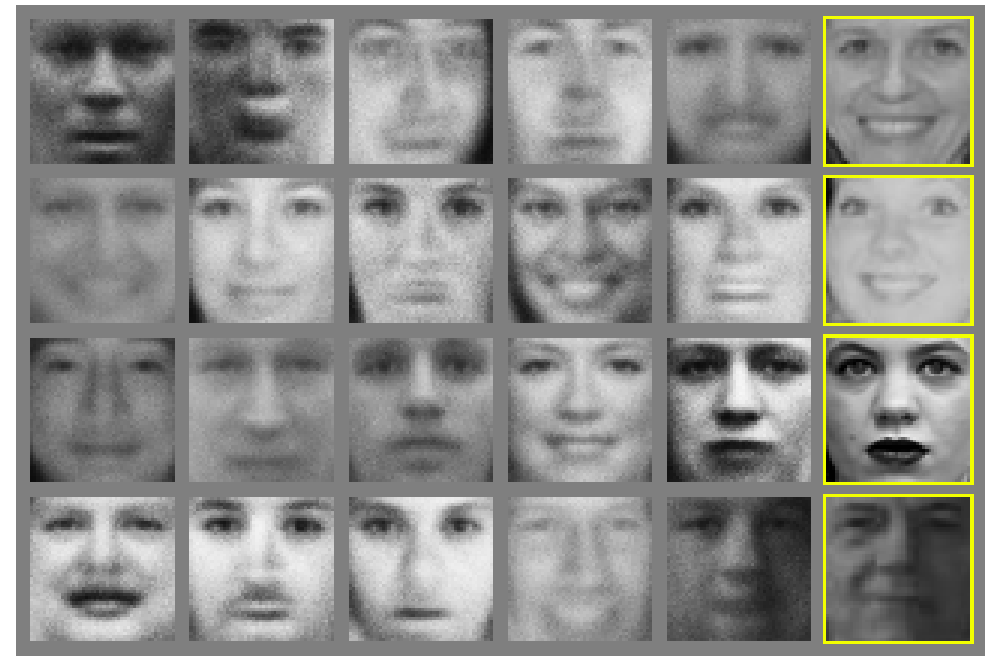

Сравним с результатами генерации [DCGAN](https://pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html) из 2016 года:

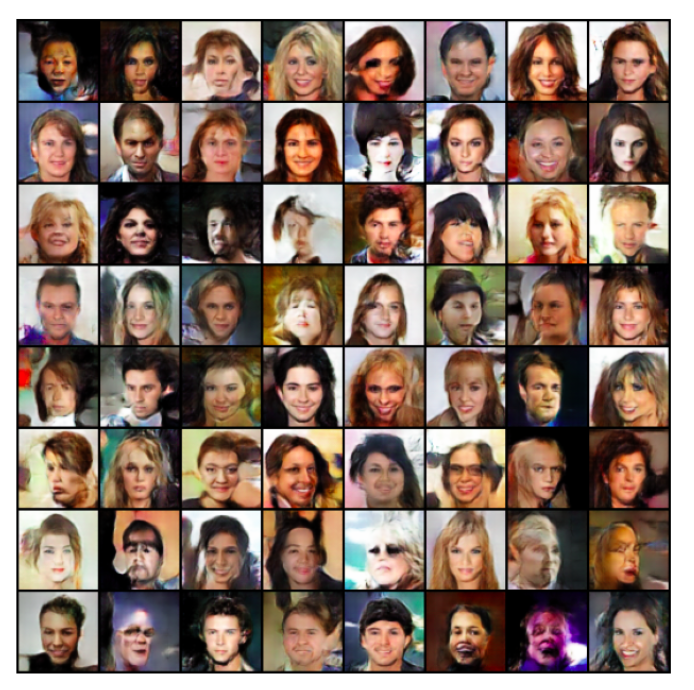

Прошло 2 года, при этом качество генерации заметно возросло (переход от черно-белых изображений к цветным крайне сложный).Что же поменялось за это время?

1) Люди перешли к сверточным нейронным сетям и стали использовать модели с большим числом параметров;

2) Научились правильнее настраивать параметры модели и архитектуры.

Но самое важное, придумали кучу разных трюков, как учить GAN. [Примеры, обязательные к прочтению](https://github.com/soumith/ganhacks), [а также менее обязательные к прочтению](https://arxiv.org/pdf/1701.04862.pdf)

Примеры основных трюков:
- Нормализация входа;
- Сэмплировать шум $z$ для генератора не равномерным, а из сферы (нормальный);
- Использовать SGD для дискриминатора и Adam для генератора (для новых моделей не актуально);
- Избегать MaxPool, использовать stride свертки;
- Использовать replay buffer (сохранять сгенерированные изображения в буффер и использовать для обучения дискриминатора в будущем);
- Зашумлять входы в дискриминатор;
- Всегда использовать Dropout в генераторе (в eval и train режимах);
- И ещё много всего...

## 3. WGAN практика MNIST


Мы будем реализовать Wasserstein GAN с gradient penalty, так как благодаря нему модель лучше учится и градиенты меньше затухают.

Реализация взята из [GitHub](https://github.com/eriklindernoren/PyTorch-GAN), в котором реализован зоопарк GAN моделей.

### 3.1 WGAN



[WGAN](https://arxiv.org/abs/1701.07875) модель использует клиппинг весов для достижения Липшицевости функции критика.

Функция потерь
$$
\min_{G} W(\pi || p) \approx \min_{G} \max_{\boldsymbol{\phi} \in \boldsymbol{\Phi}} \left[ \mathbb{E}_{\pi(\mathbf{x})} f(\mathbf{x}, \boldsymbol{\phi})  - \mathbb{E}_{p(\mathbf{z})} f(G(\mathbf{z}, \boldsymbol{\theta}), \boldsymbol{\phi} )\right].
$$

Здесь $f(\mathbf{x}, \boldsymbol{\phi})$ модель критика. Веса критика $\boldsymbol{\phi}$ должны принадлежать компакту $\boldsymbol{\Phi} = [-c, c]^d$.

## 3.2 WGAN-GP

[WGAN-GP](https://arxiv.org/pdf/1704.00028.pdf) модель использует gradient penalty для достижения Липшицевости функции критика.

Функция потерь
$$
    W(\pi || p) = \underbrace{\mathbb{E}_{\pi(\mathbf{x})} f(\mathbf{x})  - \mathbb{E}_{p(\mathbf{x} | \boldsymbol{\theta})} f(\mathbf{x})}_{\text{original critic loss}} + \lambda \underbrace{\mathbb{E}_{U[0, 1]} \left[ \left( \| \nabla_{\hat{\mathbf{x}}} f(\hat{\mathbf{x}}) \|_2 - 1 \right) ^ 2\right]}_{\text{gradient penalty}},
$$
где сэмплы $\hat{\mathbf{x}}_t = t \mathbf{x} + (1 - t) \mathbf{y}$ с $t \in [0, 1]$ равномерно засэмплированы вдоль прямой соединяющей точки: $\mathbf{x}$ из распределения данных $\pi(\mathbf{x})$ и $\mathbf{y}$ распределения генератора $p(\mathbf{x} \mid \boldsymbol{\theta})$.